# Video Anomaly Detection with PyTorch LSTM

This notebook builds a **video-level normal/anomaly classifier** from scratch using pre-extracted temporal features. It includes dataset inspection, preprocessing, training, evaluation, plots, and inference.

**Expected local paths**
- Dataset: `~/Desktop/archive/All_Data`
- Project folder: `~/Desktop/urop1`

> The dataset previously inspected contains feature text files shaped like `(32, 4096)`. Each row represents one temporal segment and each column is a feature. The notebook discovers the actual folder structure instead of assuming every split filename.
>
> **Important:** If only video-level labels are available, segment-level curves are weakly supervised estimates, not verified frame-level detections. The optional temporal-annotation section uses ground-truth temporal annotations if the dataset contains them.

## 1. Install / import dependencies

Run the install cell only if an import fails. On Apple Silicon, install a PyTorch build that supports MPS. Python 3.14 package compatibility can vary; if installation fails, use a Python version supported by the current PyTorch release (for example Python 3.12 or 3.13).

In [1]:
%pip install -U numpy pandas matplotlib scikit-learn torch

  Using cached numpy-2.5.4-cp314-cp314-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached scikit_learn-1.9.1-cp314-cp314-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached torch-2.14.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (39 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
Using cached numpy-2.5.4-cp314-cp314-macosx_14_0_arm64.whl (5.5 MB)
   ━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/11.3 MB 26.9 kB/s eta 0:06:20m
Resuming download pandas-3.1.0-cp314-cp314-macosx_11_0_arm64.whl (1.0 MB/11.3 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━ 8.4/11.3 MB 290.8 kB/s eta 0:00:10
Resuming download pandas-3.1.0-cp314-cp314-macosx_11_0_arm64.whl (8.4 MB/11.3 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 946.1 kB/s  0:00:03a 0:00:010:00:0102
Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl (9.3 MB)
Using cached scikit_learn-1.9.1-cp314-cp314-maco

In [1]:
from pathlib import Path
import os, re, random, json, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_auc_score, roc_curve, precision_recall_fscore_support
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_ROOT = Path.home() / "Desktop" / "archive" / "All_Data"
PROJECT_DIR = Path.home() / "Desktop" / "urop1"
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = PROJECT_DIR / "best_lstm_model.pt"

DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Dataset root:", DATA_ROOT)
print("Project directory:", PROJECT_DIR)
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("MPS available:", torch.backends.mps.is_available())

if not DATA_ROOT.exists():
    raise FileNotFoundError(f"Dataset folder not found: {DATA_ROOT}")

Dataset root: /Users/administrator/Desktop/archive/All_Data
Project directory: /Users/administrator/Desktop/urop1
PyTorch: 2.14.1
Device: mps
MPS available: True


## 2. Inspect the dataset before loading it

This shows a sample of the files and feature-text files. Confirm the printed root and examples match the dataset you already extracted.

In [2]:
all_files = [p for p in DATA_ROOT.rglob("*") if p.is_file()]
print(f"Total files: {len(all_files):,}")
print("\nFirst 40 files:")
for p in all_files[:40]:
    print(p.relative_to(DATA_ROOT))

txt_files = [p for p in all_files if p.suffix.lower() == ".txt"]
print(f"\nTXT files: {len(txt_files):,}")
print("\nLikely split / annotation files:")
for p in txt_files:
    n = p.name.lower()
    if any(k in n for k in ["train", "test", "split", "annotation", "label"]):
        print(p.relative_to(DATA_ROOT))

Total files: 1,904

First 40 files:
.DS_Store
All_Data/.DS_Store
All_Data/Normal_Train.txt
All_Data/Anomaly_Train.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_597_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_890_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_015_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_722_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_905_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_932_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_873_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_360_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_018_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_941_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_923_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_914_x264_C.txt
All_Data/Testing_N

## 3. Find and parse feature files

Feature files are expected to be numeric text matrices, commonly `(32, 4096)`. Split files and annotation files are excluded. A file is accepted as a feature file only if it can be parsed as a 2-D numeric matrix.

In [3]:
NON_FEATURE_NAME_HINTS = (
    "train", "test", "split", "annotation", "label", "readme", "license"
)

def try_load_feature_file(path):
    try:
        arr = np.loadtxt(path, dtype=np.float32)
        if arr.ndim == 1:
            # A single row is not expected for this temporal LSTM pipeline.
            return None
        if arr.ndim == 2 and arr.shape[0] >= 2 and arr.shape[1] >= 2:
            if np.isfinite(arr).all():
                return arr
    except Exception:
        pass
    return None

feature_records = []
rejected = 0

for p in txt_files:
    if any(hint in p.name.lower() for hint in NON_FEATURE_NAME_HINTS):
        # Some feature filenames may contain these words; try parsing anyway.
        pass
    arr = try_load_feature_file(p)
    if arr is None:
        rejected += 1
        continue
    feature_records.append({
        "path": p,
        "relative_path": str(p.relative_to(DATA_ROOT)),
        "video_id": p.stem,
        "shape": tuple(arr.shape),
        "features": arr
    })

print("Numeric feature matrices found:", len(feature_records))
print("Other/unreadable TXT files skipped:", rejected)
if not feature_records:
    raise RuntimeError(
        "No numeric 2-D feature matrices were found. Inspect the file listing above "
        "and update the feature-file parser for your dataset format."
    )

shape_counts = Counter(rec["shape"] for rec in feature_records)
print("Most common feature shapes:", shape_counts.most_common(10))
display(pd.DataFrame([
    {"relative_path": r["relative_path"], "video_id": r["video_id"], "shape": str(r["shape"])}
    for r in feature_records[:15]
]))

Numeric feature matrices found: 1900
Other/unreadable TXT files skipped: 2
Most common feature shapes: [((32, 4096), 1900)]


,relative_path,video_id,shape
0,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_597_x264_C,"(32, 4096)"
1,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_890_x264_C,"(32, 4096)"
2,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_015_x264_C,"(32, 4096)"
3,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_722_x264_C,"(32, 4096)"
4,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_905_x264_C,"(32, 4096)"
5,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_932_x264_C,"(32, 4096)"
6,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_873_x264_C,"(32, 4096)"
7,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_360_x264_C,"(32, 4096)"
8,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_018_x264_C,"(32, 4096)"
9,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_941_x264_C,"(32, 4096)"


## 4. Assign video labels

UCF-Crime feature folders commonly use anomaly category names (for example `Abuse`, `Arson`, `Arrest`) and normal-video folders. The code identifies labels from folder names and path context. Review the label summary and unknown examples before training.

Label convention: `0 = Normal`, `1 = Anomaly`.

In [4]:
NORMAL_HINTS = {"normal", "normalvideos", "normal_video", "normalvideospart1", "normalvideospart2"}
ANOMALY_CATEGORIES = {
    "abuse", "arrest", "arson", "assault", "burglary", "explosion", "fighting",
    "robbery", "shooting", "shoplifting", "stealing", "vandalism", "roadaccidents",
    "road_accidents", "accident", "terrorism", "weapon", "robbery", "abuse"
}

def normalize_token(s):
    return re.sub(r"[^a-z0-9]", "", s.lower())

def infer_label(path):
    parts = [normalize_token(part) for part in path.parts]
    # Explicit normal folder names take precedence.
    if any(p == "normal" or p.startswith("trainingnormal") or p.startswith("testingnormal") for p in parts):
        return 0, "normal_folder"
    # Known anomaly category directory names.
    for p in parts[:-1]:
        if p in ANOMALY_CATEGORIES or any(p.startswith(cat) for cat in ANOMALY_CATEGORIES):
            return 1, "anomaly_category"
    # Some datasets store anomaly categories in a parent directory named with "Anomaly".
    if any("anomaly" in p for p in parts[:-1]):
        return 1, "anomaly_parent"
    # A file path that explicitly indicates normal videos.
    joined = "/".join(parts)
    if "normal" in joined:
        return 0, "normal_path"
    return None, "unknown"

for rec in feature_records:
    label, source = infer_label(rec["path"])
    rec["label"] = label
    rec["label_source"] = source

label_summary = Counter(str(r["label"]) for r in feature_records)
source_summary = Counter(r["label_source"] for r in feature_records)
print("Raw label counts (None means unresolved):", label_summary)
print("Label inference sources:", source_summary)

unknown = [r for r in feature_records if r["label"] is None]
if unknown:
    print("\nExamples with unresolved labels (up to 30):")
    for r in unknown[:30]:
        print(r["relative_path"])

# Keep only records whose labels were inferred; do not silently guess unknown labels.
records = [r for r in feature_records if r["label"] in (0, 1)]
if len(records) < len(feature_records):
    print(f"\nExcluded {len(feature_records) - len(records)} files with unresolved labels.")
if len(set(r["label"] for r in records)) < 2:
    raise RuntimeError(
        "Both classes were not detected. Check the printed paths and edit infer_label() "
        "to match the exact folder names in your dataset."
    )

print("\nUsable labelled videos:", len(records))
print("Usable class counts:", Counter(r["label"] for r in records))

Raw label counts (None means unresolved): Counter({'0': 950, '1': 950})
Label inference sources: Counter({'normal_folder': 950, 'anomaly_category': 950})

Usable labelled videos: 1900
Usable class counts: Counter({0: 950, 1: 950})


## 5. Visualize class balance and feature statistics

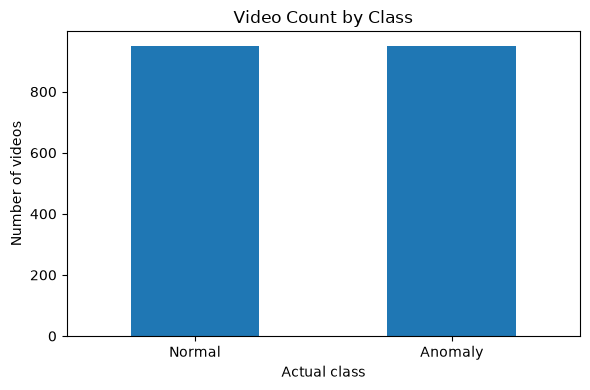

Example video: Normal_Videos_597_x264_C
Feature shape: (32, 4096)
Min / max / mean / std: 0.0 0.13075600564479828 0.006569992750883102 0.014176595956087112


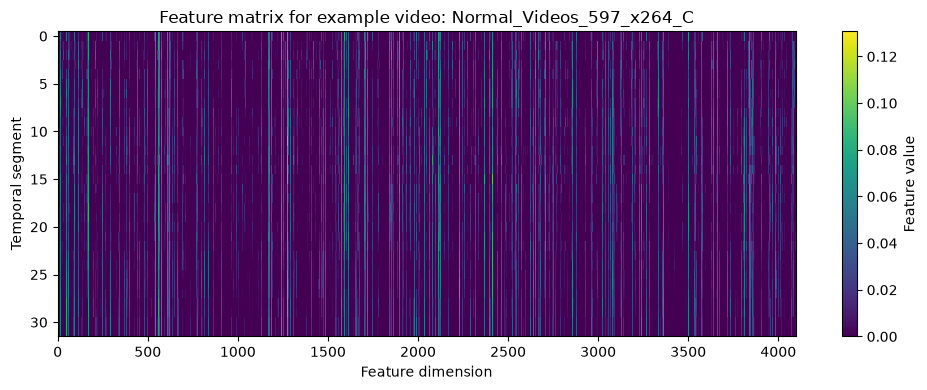

In [5]:
class_counts = pd.Series([r["label"] for r in records]).map({0: "Normal", 1: "Anomaly"}).value_counts()
plt.figure(figsize=(6, 4))
class_counts.reindex(["Normal", "Anomaly"]).plot(kind="bar")
plt.title("Video Count by Class")
plt.xlabel("Actual class")
plt.ylabel("Number of videos")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

example = records[0]["features"]
print("Example video:", records[0]["video_id"])
print("Feature shape:", example.shape)
print("Min / max / mean / std:", float(example.min()), float(example.max()),
      float(example.mean()), float(example.std()))

plt.figure(figsize=(10, 4))
plt.imshow(example, aspect="auto", interpolation="nearest")
plt.title(f"Feature matrix for example video: {records[0]['video_id']}")
plt.xlabel("Feature dimension")
plt.ylabel("Temporal segment")
plt.colorbar(label="Feature value")
plt.tight_layout()
plt.show()

## 6. Build train / validation / test splits

The code first looks for official split files and reports them. Since split formats vary, this starter notebook uses a **stratified video-level split** unless you explicitly adapt the official-split parser below. No frames from one video are split across sets.

Default: 70% train, 15% validation, 15% test. For exact comparison with a published UCF-Crime benchmark, use the official split files and verify that all IDs match.

In [6]:
# The dataset may contain official split text files. Inspect their contents before
# adapting them; formats differ (some have labels, some contain only paths).
split_candidates = [
    p for p in txt_files
    if any(k in p.name.lower() for k in ["train", "test", "split"])
    and try_load_feature_file(p) is None
]
print("Potential split files:", len(split_candidates))
for p in split_candidates[:20]:
    print("\n---", p.relative_to(DATA_ROOT), "---")
    try:
        print("\n".join(p.read_text(errors="ignore").splitlines()[:5]))
    except Exception as e:
        print("Could not read:", e)

# Stratified fallback split by video. Change this only after validating official IDs.
labels = np.array([r["label"] for r in records], dtype=np.int64)
indices = np.arange(len(records))
train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, random_state=SEED, stratify=labels
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED,
    stratify=labels[temp_idx]
)

train_records = [records[i] for i in train_idx]
val_records = [records[i] for i in val_idx]
test_records = [records[i] for i in test_idx]

def show_split(name, subset):
    c = Counter(r["label"] for r in subset)
    print(f"{name:>10}: {len(subset):4d} videos | Normal={c.get(0,0)} | Anomaly={c.get(1,0)}")

show_split("Train", train_records)
show_split("Validation", val_records)
show_split("Test", test_records)

Potential split files: 2

--- All_Data/Normal_Train.txt ---
Training-Normal-Videos-Part-1-txt/Normal_Videos001_x264_C.txt
Training-Normal-Videos-Part-1-txt/Normal_Videos002_x264_C.txt
Training-Normal-Videos-Part-1-txt/Normal_Videos004_x264_C.txt
Training-Normal-Videos-Part-1-txt/Normal_Videos005_x264_C.txt
Training-Normal-Videos-Part-1-txt/Normal_Videos007_x264_C.txt

--- All_Data/Anomaly_Train.txt ---
Anomaly-Vidoes-Part-1-txt/Abuse/Abuse001_x264_C.txt
Anomaly-Vidoes-Part-1-txt/Abuse/Abuse002_x264_C.txt
Anomaly-Vidoes-Part-1-txt/Abuse/Abuse003_x264_C.txt
Anomaly-Vidoes-Part-1-txt/Abuse/Abuse004_x264_C.txt
Anomaly-Vidoes-Part-1-txt/Abuse/Abuse005_x264_C.txt
     Train: 1330 videos | Normal=665 | Anomaly=665
Validation:  285 videos | Normal=142 | Anomaly=143
      Test:  285 videos | Normal=143 | Anomaly=142


## 7. Normalize features using training data only

Each video is a sequence of feature vectors. Sequences are padded or truncated to a common length so they can be batched. The normalization statistics are calculated from training data only to avoid test-set leakage.

In [7]:
# All videos should usually have the same sequence length and feature dimension.
feature_dims = Counter(r["features"].shape[1] for r in records)
print("Feature dimension counts:", feature_dims)
if len(feature_dims) != 1:
    raise ValueError("Feature dimensions differ across files. Add a consistent feature alignment step.")

INPUT_DIM = next(iter(feature_dims))
SEQ_LEN = int(np.median([r["features"].shape[0] for r in train_records]))
print("Input dimension:", INPUT_DIM)
print("Sequence length used:", SEQ_LEN)

train_rows = np.concatenate([r["features"] for r in train_records], axis=0)
FEATURE_MEAN = train_rows.mean(axis=0, keepdims=True)
FEATURE_STD = train_rows.std(axis=0, keepdims=True)
FEATURE_STD[FEATURE_STD < 1e-6] = 1.0

def prepare_sequence(arr):
    arr = np.asarray(arr, dtype=np.float32)
    arr = (arr - FEATURE_MEAN) / FEATURE_STD
    if arr.shape[0] >= SEQ_LEN:
        # Evenly sample across the whole video rather than only taking the beginning.
        chosen = np.linspace(0, arr.shape[0] - 1, SEQ_LEN).round().astype(int)
        arr = arr[chosen]
    else:
        pad = np.zeros((SEQ_LEN - arr.shape[0], arr.shape[1]), dtype=np.float32)
        arr = np.concatenate([arr, pad], axis=0)
    return arr.astype(np.float32)

class VideoFeatureDataset(Dataset):
    def __init__(self, subset):
        self.subset = subset
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, idx):
        rec = self.subset[idx]
        x = prepare_sequence(rec["features"])
        y = np.float32(rec["label"])
        return torch.from_numpy(x), torch.tensor(y), rec["video_id"]

BATCH_SIZE = 8
train_loader = DataLoader(VideoFeatureDataset(train_records), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(VideoFeatureDataset(val_records), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(VideoFeatureDataset(test_records), batch_size=BATCH_SIZE, shuffle=False)

xb, yb, ids = next(iter(train_loader))
print("Batch feature tensor:", tuple(xb.shape))  # (batch, sequence, feature_dim)
print("Batch labels:", yb.tolist())
print("Example IDs:", list(ids)[:3])

Feature dimension counts: Counter({4096: 1900})
Input dimension: 4096
Sequence length used: 32
Batch feature tensor: (8, 32, 4096)
Batch labels: [1.0, 1.0, 1.0, 1.0, 1.0, 0.0, 1.0, 1.0]
Example IDs: ['RoadAccidents111_x264_C', 'RoadAccidents140_x264_C', 'Vandalism036_x264_C']


## 8. Define the LSTM classifier

The LSTM reads temporal feature vectors and predicts one class per video. A second head emits a score for each temporal segment; this score is useful for exploratory timelines but is not a properly supervised frame-level detector unless temporal ground-truth labels are used during training.

In [8]:
class VideoAnomalyLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_layers=1, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=False
        )
        self.dropout = nn.Dropout(dropout)
        self.video_head = nn.Linear(hidden_dim, 1)
        self.segment_head = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        sequence_out, (h_n, c_n) = self.lstm(x)
        segment_logits = self.segment_head(self.dropout(sequence_out)).squeeze(-1)
        video_logits = self.video_head(self.dropout(sequence_out[:, -1, :])).squeeze(-1)
        return video_logits, segment_logits

HIDDEN_DIM = 128
model = VideoAnomalyLSTM(INPUT_DIM, hidden_dim=HIDDEN_DIM).to(DEVICE)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

VideoAnomalyLSTM(
  (lstm): LSTM(4096, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (video_head): Linear(in_features=128, out_features=1, bias=True)
  (segment_head): Linear(in_features=128, out_features=1, bias=True)
)
Trainable parameters: 2163970


## 9. Train the model

Training and validation metrics are collected every epoch. The best checkpoint is selected by validation loss. The main classification objective is video-level binary cross entropy.

In [9]:
EPOCHS = 20
LEARNING_RATE = 1e-4
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-5)

history = {
    "train_loss": [], "val_loss": [],
    "train_accuracy": [], "val_accuracy": [],
    "train_auc": [], "val_auc": []
}
best_val_loss = float("inf")
best_epoch = 0

def run_epoch(loader, training):
    model.train(training)
    total_loss, total_count = 0.0, 0
    all_y, all_prob = [], []
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for xb, yb, _ in loader:
            xb = xb.to(DEVICE, dtype=torch.float32)
            yb = yb.to(DEVICE, dtype=torch.float32)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits, _ = model(xb)
            loss = criterion(logits, yb)
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                optimizer.step()
            probs = torch.sigmoid(logits)
            total_loss += loss.item() * len(yb)
            total_count += len(yb)
            all_y.extend(yb.detach().cpu().numpy().astype(int).tolist())
            all_prob.extend(probs.detach().cpu().numpy().tolist())
    y_true = np.asarray(all_y)
    y_prob = np.asarray(all_prob)
    y_pred = (y_prob >= 0.5).astype(int)
    acc = accuracy_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else float("nan")
    return total_loss / max(total_count, 1), acc, auc

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc, train_auc = run_epoch(train_loader, training=True)
    val_loss, val_acc, val_auc = run_epoch(val_loader, training=False)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)
    history["train_auc"].append(train_auc)
    history["val_auc"].append(val_auc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "input_dim": INPUT_DIM,
            "hidden_dim": HIDDEN_DIM,
            "seq_len": SEQ_LEN,
            "feature_mean": FEATURE_MEAN,
            "feature_std": FEATURE_STD,
            "best_val_loss": best_val_loss,
        }, CHECKPOINT_PATH)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train_loss={train_loss:.4f} train_acc={train_acc:.3f} "
        f"val_loss={val_loss:.4f} val_acc={val_acc:.3f} "
        f"val_auc={val_auc:.3f}"
        + ("  [best checkpoint]" if epoch == best_epoch else "")
    )

print(f"Best epoch: {best_epoch}, best validation loss: {best_val_loss:.4f}")
print("Checkpoint saved to:", CHECKPOINT_PATH)

Epoch 01/20 | train_loss=0.6377 train_acc=0.653 val_loss=0.5887 val_acc=0.758 val_auc=0.841  [best checkpoint]
Epoch 02/20 | train_loss=0.4875 train_acc=0.883 val_loss=0.5371 val_acc=0.772 val_auc=0.874  [best checkpoint]
Epoch 03/20 | train_loss=0.3800 train_acc=0.942 val_loss=0.4939 val_acc=0.807 val_auc=0.896  [best checkpoint]
Epoch 04/20 | train_loss=0.2922 train_acc=0.966 val_loss=0.4595 val_acc=0.842 val_auc=0.904  [best checkpoint]
Epoch 05/20 | train_loss=0.2198 train_acc=0.986 val_loss=0.4342 val_acc=0.835 val_auc=0.908  [best checkpoint]
Epoch 06/20 | train_loss=0.1647 train_acc=0.996 val_loss=0.4168 val_acc=0.835 val_auc=0.909  [best checkpoint]
Epoch 07/20 | train_loss=0.1245 train_acc=0.997 val_loss=0.4037 val_acc=0.832 val_auc=0.911  [best checkpoint]
Epoch 08/20 | train_loss=0.0936 train_acc=0.998 val_loss=0.3927 val_acc=0.835 val_auc=0.914  [best checkpoint]
Epoch 09/20 | train_loss=0.0722 train_acc=0.999 val_loss=0.3857 val_acc=0.825 val_auc=0.914  [best checkpoint]
E

## 10. Plot training and validation curves

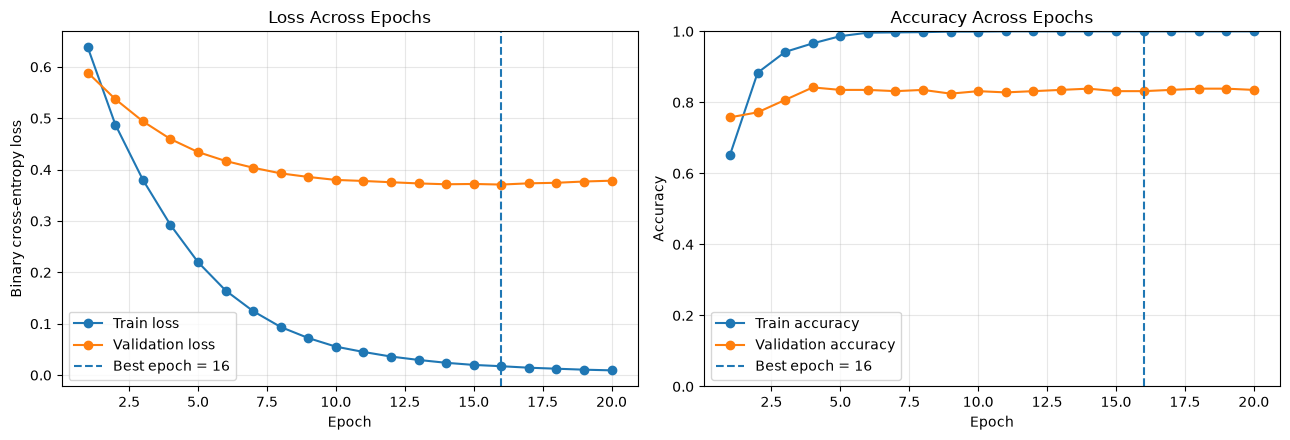

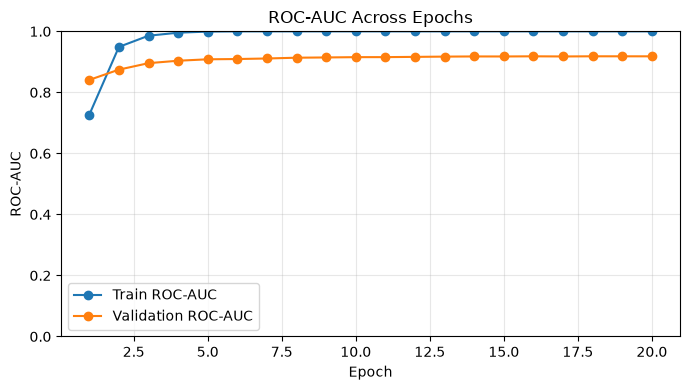

In [10]:
epochs_axis = np.arange(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(epochs_axis, history["train_loss"], marker="o", label="Train loss")
axes[0].plot(epochs_axis, history["val_loss"], marker="o", label="Validation loss")
axes[0].axvline(best_epoch, linestyle="--", label=f"Best epoch = {best_epoch}")
axes[0].set_title("Loss Across Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_axis, history["train_accuracy"], marker="o", label="Train accuracy")
axes[1].plot(epochs_axis, history["val_accuracy"], marker="o", label="Validation accuracy")
axes[1].axvline(best_epoch, linestyle="--", label=f"Best epoch = {best_epoch}")
axes[1].set_title("Accuracy Across Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(epochs_axis, history["train_auc"], marker="o", label="Train ROC-AUC")
plt.plot(epochs_axis, history["val_auc"], marker="o", label="Validation ROC-AUC")
plt.title("ROC-AUC Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Load the best checkpoint and evaluate on the held-out test set

In [11]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print("Loaded checkpoint from epoch:", checkpoint["epoch"])

test_y, test_prob, test_ids, test_segment_scores = [], [], [], []
with torch.no_grad():
    for xb, yb, batch_ids in test_loader:
        xb = xb.to(DEVICE, dtype=torch.float32)
        video_logits, segment_logits = model(xb)
        video_probs = torch.sigmoid(video_logits).cpu().numpy()
        segment_probs = torch.sigmoid(segment_logits).cpu().numpy()
        test_y.extend(yb.numpy().astype(int).tolist())
        test_prob.extend(video_probs.tolist())
        test_ids.extend(list(batch_ids))
        test_segment_scores.extend(segment_probs.tolist())

test_y = np.asarray(test_y, dtype=int)
test_prob = np.asarray(test_prob, dtype=float)
test_pred = (test_prob >= 0.5).astype(int)

print("Test videos:", len(test_y))
print("Test accuracy:", f"{accuracy_score(test_y, test_pred):.4f}")
if len(np.unique(test_y)) == 2:
    print("Test ROC-AUC:", f"{roc_auc_score(test_y, test_prob):.4f}")
print("\nClassification report:")
print(classification_report(test_y, test_pred, labels=[0, 1],
                            target_names=["Normal", "Anomaly"], zero_division=0))

test_results = pd.DataFrame({
    "video_id": test_ids,
    "actual_label": test_y,
    "predicted_label": test_pred,
    "anomaly_probability": test_prob,
    "predicted_class": np.where(test_pred == 1, "Anomaly", "Normal")
})
display(test_results.head(20))
test_results.to_csv(PROJECT_DIR / "test_predictions.csv", index=False)

Loaded checkpoint from epoch: 16
Test videos: 285
Test accuracy: 0.7930
Test ROC-AUC: 0.8721

Classification report:
              precision    recall  f1-score   support

      Normal       0.77      0.85      0.80       143
     Anomaly       0.83      0.74      0.78       142

    accuracy                           0.79       285
   macro avg       0.80      0.79      0.79       285
weighted avg       0.80      0.79      0.79       285



,video_id,actual_label,predicted_label,anomaly_probability,predicted_class
0,Arson048_x264_C,1,1,0.991196,Anomaly
1,Normal_Videos552_x264_C,0,0,0.031432,Normal
2,Normal_Videos468_x264_C,0,1,0.500157,Anomaly
3,Burglary085_x264_C,1,0,0.358598,Normal
4,Arrest006_x264_C,1,1,0.844860,Anomaly
5,Normal_Videos_758_x264_C,0,0,0.030879,Normal
6,Normal_Videos336_x264_C,0,0,0.244334,Normal
7,Normal_Videos918_x264_C,0,0,0.127531,Normal
8,Normal_Videos_246_x264_C,0,0,0.031772,Normal
9,Robbery139_x264_C,1,1,0.938764,Anomaly


## 12. Confusion matrix with labelled axes

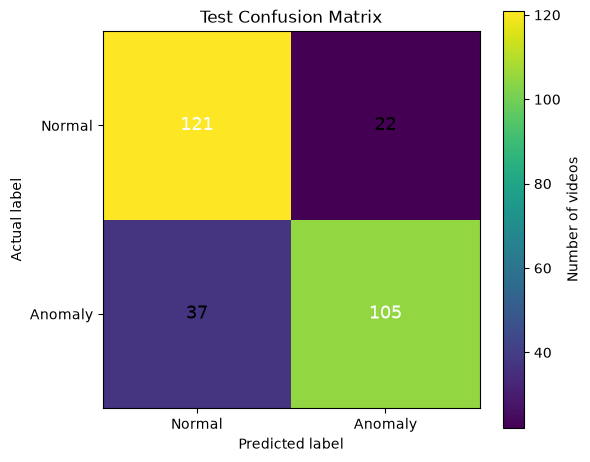

In [12]:
cm = confusion_matrix(test_y, test_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, interpolation="nearest")
ax.set_title("Test Confusion Matrix")
fig.colorbar(im, ax=ax, label="Number of videos")
classes = ["Normal", "Anomaly"]
ax.set_xticks([0, 1], labels=classes)
ax.set_yticks([0, 1], labels=classes)
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
threshold = cm.max() / 2 if cm.size else 0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, f"{cm[i, j]:d}", ha="center", va="center",
                color="white" if cm[i, j] > threshold else "black", fontsize=13)
plt.tight_layout()
plt.show()

## 13. ROC curve and class-wise precision / recall / F1

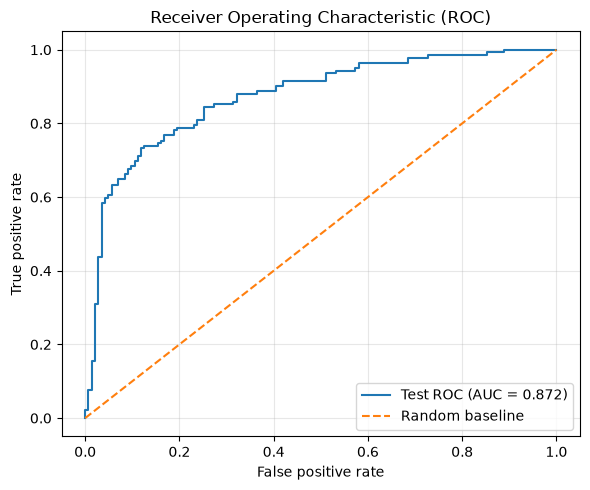

,Precision,Recall,F1-score,Support
Class,,,,
Normal,0.766,0.846,0.804,143
Anomaly,0.827,0.739,0.781,142


In [13]:
if len(np.unique(test_y)) == 2:
    fpr, tpr, _ = roc_curve(test_y, test_prob)
    auc_value = roc_auc_score(test_y, test_prob)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"Test ROC (AUC = {auc_value:.3f})")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
    plt.title("Receiver Operating Characteristic (ROC)")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

prec, rec, f1, support = precision_recall_fscore_support(
    test_y, test_pred, labels=[0, 1], zero_division=0
)
metric_df = pd.DataFrame({
    "Class": ["Normal", "Anomaly"],
    "Precision": prec, "Recall": rec, "F1-score": f1, "Support": support
})
display(metric_df.set_index("Class").style.format({
    "Precision": "{:.3f}", "Recall": "{:.3f}", "F1-score": "{:.3f}", "Support": "{:.0f}"
}))

## 14. Actual vs. estimated anomaly timeline for a test video

The model produces one score per feature segment. The plot below compares:
- **Estimated anomaly score** for each temporal segment.
- **Estimated binary segment label** using threshold 0.5.
- **Video-level actual label** as a reference.

Because training uses only video-level labels, the segment scores are not guaranteed to localize the actual anomalous frames. The optional annotation section below shows how to compare against temporal ground truth when it is available.

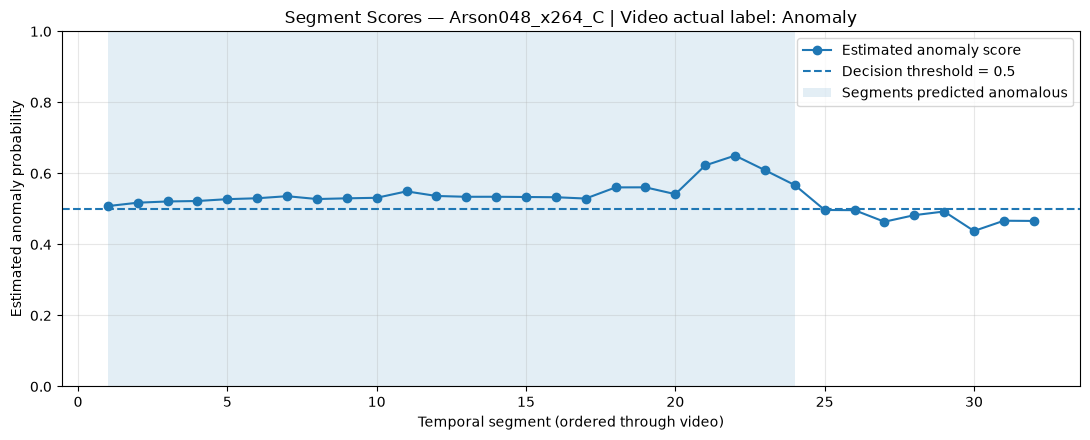

In [15]:
# Pick one anomalous test video if possible; otherwise use the first test example.
candidate_indices = np.where(test_y == 1)[0]
plot_i = int(candidate_indices[0]) if len(candidate_indices) else 0
chosen_id = test_ids[plot_i]
chosen_actual = int(test_y[plot_i])
chosen_score = test_segment_scores[plot_i]
segment_axis = np.arange(1, len(chosen_score) + 1)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(segment_axis, chosen_score, marker="o", label="Estimated anomaly score")
ax.axhline(0.5, linestyle="--", label="Decision threshold = 0.5")
ax.fill_between(segment_axis, 0, 1, where=np.asarray(chosen_score) >= 0.5, alpha=0.12,
                 transform=ax.get_xaxis_transform(), label="Segments predicted anomalous")
ax.set_ylim(0, 1)
ax.set_title(f"Segment Scores — {chosen_id} | Video actual label: {'Anomaly' if chosen_actual else 'Normal'}")
ax.set_xlabel("Temporal segment (ordered through video)")
ax.set_ylabel("Estimated anomaly probability")
ax.legend(loc="best")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 15. Optional: load official temporal annotations if present

Some UCF-Crime dataset distributions include `Temporal_Anomaly_Annotation_for_Testing_Videos.txt` with video names, event names, and start/end frame indices. This cell searches for such a file and displays examples. The exact parser depends on the file's actual format, so it does not silently fabricate segment ground truth.

In [16]:
annotation_files = [
    p for p in DATA_ROOT.rglob("*")
    if p.is_file() and "temporal" in p.name.lower() and "annotation" in p.name.lower()
]
if not annotation_files:
    print("No temporal annotation file found under DATA_ROOT.")
else:
    annotation_path = annotation_files[0]
    print("Found:", annotation_path)
    print("\nFirst 30 lines:")
    print("\n".join(annotation_path.read_text(errors="ignore").splitlines()[:30]))
    print(
        "\nInspect this format. If it contains video name + start frame + end frame, "
        "parse those fields and map the annotated frame ranges onto temporal segments. "
        "Use the dataset's documented frame rate / segment sampling to make this mapping."
    )

No temporal annotation file found under DATA_ROOT.


## 16. Reusable inference function

Use this function with any feature `.txt` file that contains the same feature type used for training. It prints a video-level prediction and plots the segment scores.

In [17]:
def predict_video_feature_file(feature_path, threshold=0.5, show_plot=True):
    feature_path = Path(feature_path)
    arr = try_load_feature_file(feature_path)
    if arr is None:
        raise ValueError(f"Could not read a numeric 2-D feature matrix: {feature_path}")

    x = torch.from_numpy(prepare_sequence(arr)).unsqueeze(0).to(DEVICE, dtype=torch.float32)
    model.eval()
    with torch.no_grad():
        video_logit, segment_logits = model(x)
        anomaly_probability = float(torch.sigmoid(video_logit).item())
        segment_scores = torch.sigmoid(segment_logits).squeeze(0).cpu().numpy()

    predicted_label = int(anomaly_probability >= threshold)
    predicted_name = "Anomaly" if predicted_label else "Normal"
    print("File:", feature_path.name)
    print(f"Anomaly probability: {anomaly_probability:.4f}")
    print(f"Prediction (threshold={threshold:.2f}): {predicted_name}")

    if show_plot:
        xs = np.arange(1, len(segment_scores) + 1)
        plt.figure(figsize=(10, 4))
        plt.plot(xs, segment_scores, marker="o", label="Estimated segment anomaly score")
        plt.axhline(threshold, linestyle="--", label=f"Threshold = {threshold:.2f}")
        plt.ylim(0, 1)
        plt.title(f"Inference timeline: {feature_path.stem} — {predicted_name}")
        plt.xlabel("Temporal segment")
        plt.ylabel("Estimated anomaly probability")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    return {
        "video_id": feature_path.stem,
        "anomaly_probability": anomaly_probability,
        "predicted_label": predicted_label,
        "predicted_class": predicted_name,
        "segment_scores": segment_scores
    }

# Example: run this after replacing the path with a feature file from your dataset.
# sample_feature_path = records[0]["path"]
# prediction = predict_video_feature_file(sample_feature_path)

## 17. Save training history and final artifacts

In [18]:
pd.DataFrame(history).assign(epoch=np.arange(1, len(history["train_loss"]) + 1)).to_csv(
    PROJECT_DIR / "training_history.csv", index=False
)
print("Saved:")
print(" - Best checkpoint:", CHECKPOINT_PATH)
print(" - Test predictions:", PROJECT_DIR / "test_predictions.csv")
print(" - Training history:", PROJECT_DIR / "training_history.csv")
print("\nNotebook project directory:", PROJECT_DIR)

Saved:
 - Best checkpoint: /Users/administrator/Desktop/urop1/best_lstm_model.pt
 - Test predictions: /Users/administrator/Desktop/urop1/test_predictions.csv
 - Training history: /Users/administrator/Desktop/urop1/training_history.csv

Notebook project directory: /Users/administrator/Desktop/urop1
